In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

In [42]:
# Read data from file
df = pd.read_csv('D:/Data Analysis/Final Tests/boilerplate-sea-level-predictor-main/epa-sea-level.csv')
df.head()

,Year,CSIRO Adjusted Sea Level,Lower Error Bound,Upper Error Bound,NOAA Adjusted Sea Level
0,1880,0.000000,-0.952756,0.952756,NaN
1,1881,0.220472,-0.732283,1.173228,NaN
2,1882,-0.440945,-1.346457,0.464567,NaN
3,1883,-0.232283,-1.129921,0.665354,NaN
4,1884,0.590551,-0.283465,1.464567,NaN


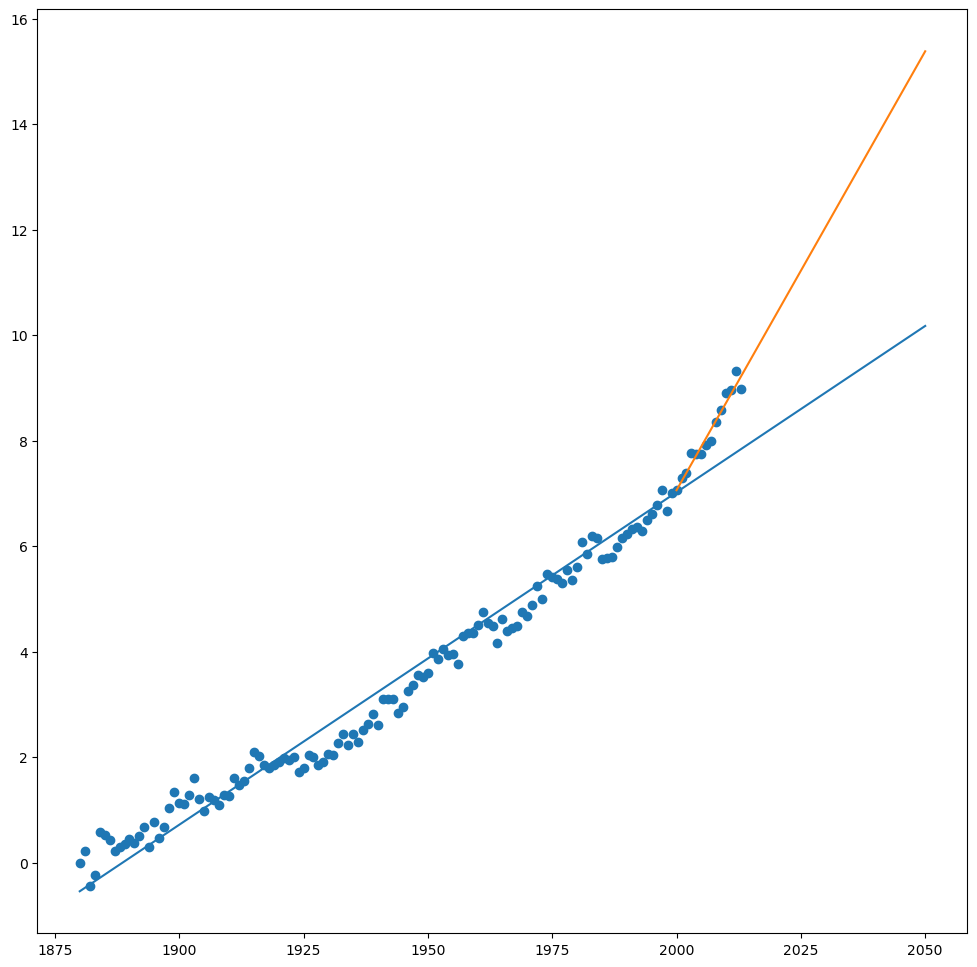

In [49]:
# Create scatter plot
fig, ax = plt.subplots(figsize=(12, 12))
ax.scatter(
    'Year',
    'CSIRO Adjusted Sea Level',
    data=df
)

# Create first line of best fit
slope1 = linregress(df['Year'], df['CSIRO Adjusted Sea Level'])[0]
y_intercept1 = linregress(df['Year'], df['CSIRO Adjusted Sea Level'])[1]
x1 = np.arange(1880, 2051)
y1 = x1*slope1 + y_intercept1
ax.plot(x1, y1)

# Create second line of best fit
slope2 = linregress(
    df.loc[df['Year']>=2000, 'Year'],
    df.loc[df['Year']>=2000, 'CSIRO Adjusted Sea Level']
)[0]
y_intercept2 = linregress(
    df.loc[df['Year']>=2000, 'Year'],
    df.loc[df['Year']>=2000, 'CSIRO Adjusted Sea Level']
)[1]
x2 = np.arange(2000, 2051)
y2 = x2*slope2 + y_intercept2
ax.plot(x2, y2)

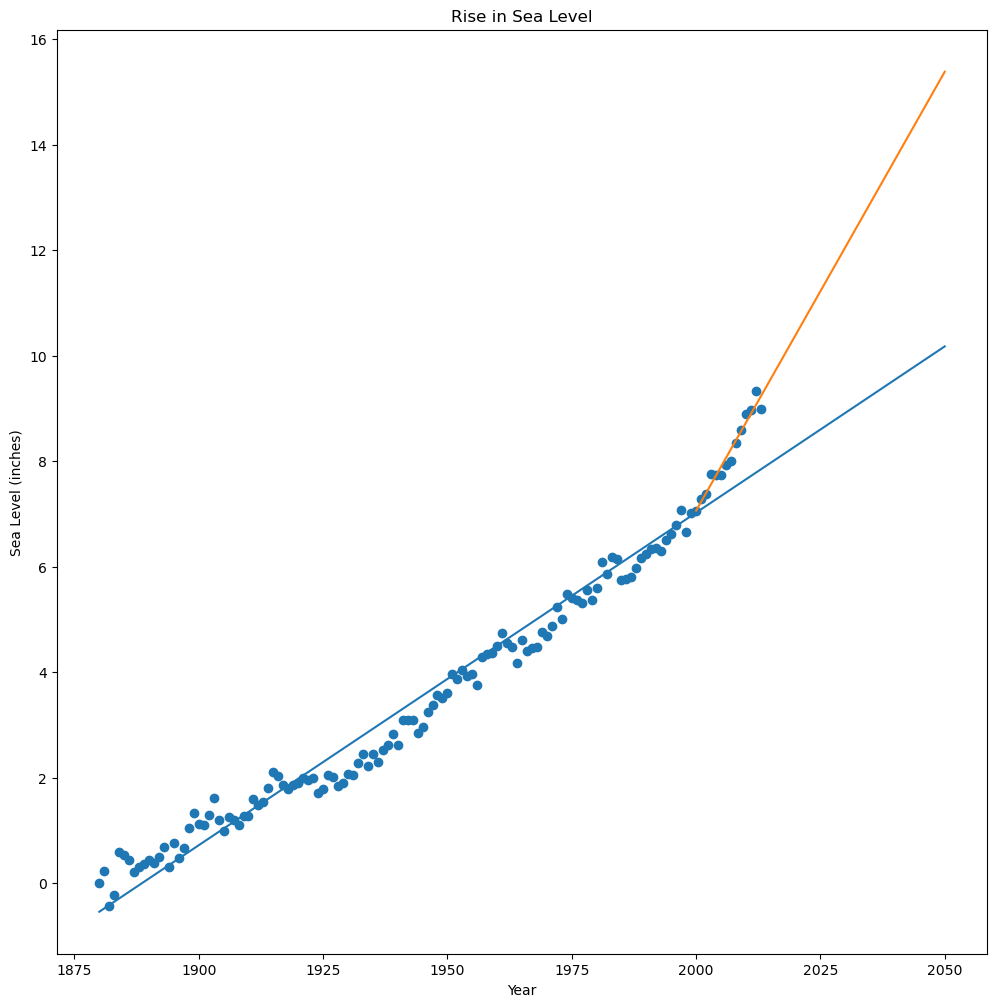

In [52]:
# Add labels and title
ax.set_xlabel('Year')
ax.set_ylabel('Sea Level (inches)')
ax.set_title('Rise in Sea Level')

fig

In [53]:
linregress?

Signature:
linregress(
    x,
    y,
    alternative='two-sided',
    *,
    axis=0,
    nan_policy='propagate',
    keepdims=False,
)
Docstring:
Calculate a linear least-squares regression for two sets of measurements.

Parameters
----------
x, y : array_like
    Two sets of measurements.  Both arrays should have the same length N.
alternative : {'two-sided', 'less', 'greater'}, optional
    Defines the alternative hypothesis. Default is 'two-sided'.
    The following options are available:
    
    * 'two-sided': the slope of the regression line is nonzero
    * 'less': the slope of the regression line is less than zero
    * 'greater':  the slope of the regression line is greater than zero
    
    .. versionadded:: 1.7.0
axis : int or None, default: 0
    If an int, the axis of the input along which to compute the statistic.
    The statistic of each axis-slice (e.g. row) of the input will appear in a
    corresponding element of the output.
    If ``None``, the input will be ravel